# House Price Prediction: Linear Regression vs Ridge

My first supervised learning project from Module 3. The goal: predict a house's sale price from things like its size, bedrooms, bathrooms and city.

How this notebook flows:

1. Load the data and see what we're working with
2. Clean it and pick the features
3. Build a simple baseline, so we know the worst "serious" score to beat
4. Train linear regression, then Ridge regression
5. Compare them properly with cross-validation
6. Plot where the best model gets it wrong

## 1. Load the data

One row per house sale. `price` is what we want to predict, everything else is a clue.

The data comes from the instructor's [DSML-Training repo](https://github.com/aamir-gk2539-byte/DSML-Training) (Module 3). The notebook uses the CSV if it's in this folder, and downloads it from the repo otherwise.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/aamir-gk2539-byte/DSML-Training/main/Module%203/House_Price_data.csv"

if os.path.exists("House_Price_data.csv"):
    df = pd.read_csv("House_Price_data.csv")
else:
    df = pd.read_csv(DATA_URL)

print(df.shape)
df.head()


(4600, 18)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


Quick health check: how many missing values does each column have, and what do the numbers roughly look like?

In [2]:
print("Missing values per column:")
print(df.isna().sum())
df.describe().T

Missing values per column:
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
price,4600.0,551962.988473,563834.702547,0.0,322875.00,460943.461539,654962.50,26590000.0
bedrooms,4600.0,3.400870,0.908848,0.0,3.00,3.000000,4.00,9.0
bathrooms,4600.0,2.160815,0.783781,0.0,1.75,2.250000,2.50,8.0
sqft_living,4600.0,2139.346957,963.206916,370.0,1460.00,1980.000000,2620.00,13540.0
sqft_lot,4600.0,14852.516087,35884.436145,638.0,5000.75,7683.000000,11001.25,1074218.0
floors,4600.0,1.512065,0.538288,1.0,1.00,1.500000,2.00,3.5
waterfront,4600.0,0.007174,0.084404,0.0,0.00,0.000000,0.00,1.0
view,4600.0,0.240652,0.778405,0.0,0.00,0.000000,0.00,4.0
condition,4600.0,3.451739,0.677230,1.0,3.00,3.000000,4.00,5.0
sqft_above,4600.0,1827.265435,862.168977,370.0,1190.00,1590.000000,2300.00,9410.0


## 2. Clean and pick features

Three things to fix before modeling:

- `date` is text right now. A model can't use "2014-05-02" directly, so I pull out the sale month and year as numbers.
- `street` is basically unique per house, so it can't generalize. `country` is "USA" for every row, so it carries no information. Both get dropped.
- `city` is a word, not a number. I'll deal with it in the pipeline below so the encoding is learned only from training data. `statezip` says the same thing as `city` at a finer grain, so the pipeline drops it to keep things simple.


In [3]:
data = df.copy()

data["date"] = pd.to_datetime(data["date"])
data["sale_month"] = data["date"].dt.month
data["sale_year"] = data["date"].dt.year

data = data.drop(columns=["date", "street", "country"])

X = data.drop(columns=["price"])
y = data["price"]
print(X.columns.tolist())

['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'city', 'statezip', 'sale_month', 'sale_year']


## 3. Train/test split

The model learns from the training set (80%) and we judge it on the test set (20%) - houses it has never seen. A good score on training data alone just means it memorized.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)
print(f"training rows: {len(X_train)}, test rows: {len(X_test)}")

training rows: 3680, test rows: 920


## 4. The baseline: always guess the average

Before any real model, a "dumb" one that ignores all features and always predicts the average training price. This is the floor. If linear regression can't beat this, something is broken.

Three scores used for every model below:

- **MAE** (mean absolute error): on average, how many dollars off is a prediction?
- **RMSE** (root mean squared error): like MAE, but big misses hurt more.
- **R2**: 1.0 is perfect, 0.0 means "no better than guessing the average", negative means worse than that.


In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def score(name, model, X_te, y_te):
    pred = model.predict(X_te)
    mae = mean_absolute_error(y_te, pred)
    rmse = np.sqrt(mean_squared_error(y_te, pred))
    r2 = r2_score(y_te, pred)
    print(f"{name:22s} MAE: {mae:>12,.0f}   RMSE: {rmse:>12,.0f}   R2: {r2:.3f}")
    return pred

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = score("baseline (mean price)", baseline, X_test, y_test)

baseline (mean price)  MAE:      239,380   RMSE:      350,356   R2: -0.007


## 5. Linear regression

Linear regression learns one weight per feature (price goes up roughly X dollars per extra square foot, and so on) and adds them up.

Two prep steps, bundled into a Pipeline so sklearn applies them in the right order and only ever learns them from training data:

- **One-hot encode `city`**: turn it into one 0/1 column per city, because a model can't multiply by the word "Seattle".
- **Scale the numeric columns**: square footage is in the thousands while bathrooms is around 2. Scaling puts them on the same footing, which matters for Ridge later.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = ["city"]

prep = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("city", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

lin_reg = Pipeline([
    ("prep", prep),
    ("model", LinearRegression()),
])

lin_reg.fit(X_train, y_train)
lin_pred = score("linear regression", lin_reg, X_test, y_test)

linear regression      MAE:      136,267   RMSE:      229,756   R2: 0.567


## 6. Ridge regression

Ridge is linear regression with a handbrake. It shrinks the weights toward zero while fitting, so no single feature gets to shout too loud. That usually makes it more stable on new data, especially with lots of one-hot city columns.

How hard it brakes is set by `alpha`. Instead of guessing, I try a few values and let grid search with cross-validation pick the best one.

In [7]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge = Pipeline([
    ("prep", prep),
    ("model", Ridge()),
])

search = GridSearchCV(
    ridge,
    {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    scoring="r2",
    cv=5,
)
search.fit(X_train, y_train)

print(f"best alpha: {search.best_params_['model__alpha']}")
ridge_pred = score("ridge regression", search.best_estimator_, X_test, y_test)

best alpha: 10
ridge regression       MAE:      137,153   RMSE:      233,412   R2: 0.553


## 7. Cross-validation: one split can be lucky

Everything above rests on one random 80/20 split. A different split could flatter or sink a model. 5-fold cross-validation fixes that: split the data into 5 parts, train on 4 and test on the 5th, rotate until every part has been the test part, then average the 5 scores.

Two rules keep it honest:

- The held-out test set stays out of this. The comparison runs on the training data only.
- Ridge's alpha is re-picked inside each fold (nested cross-validation), so it isn't tuned on the same data it's judged on.


In [8]:
from sklearn.model_selection import cross_val_score

ridge_cv = Pipeline([
    ("prep", prep),
    ("model", Ridge()),
])
ridge_search = GridSearchCV(
    ridge_cv,
    {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    scoring="r2",
    cv=5,
)

for name, model in [
    ("baseline", DummyRegressor(strategy="mean")),
    ("linear regression", lin_reg),
    ("ridge regression", ridge_search),
]:
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
    print(f"{name:20s} R2 per fold: {np.round(scores, 3)}   mean: {scores.mean():.3f} (+/- {scores.std():.3f})")


baseline             R2 per fold: [-0.    -0.001 -0.009 -0.002 -0.012]   mean: -0.005 (+/- 0.005)
linear regression    R2 per fold: [0.57  0.268 0.554 0.088 0.484]   mean: 0.393 (+/- 0.187)


ridge regression     R2 per fold: [0.574 0.25  0.549 0.088 0.493]   mean: 0.391 (+/- 0.190)


## 8. Where does the model go wrong?

Linear and Ridge land within noise of each other, and their error patterns look the same, so here's the Ridge model's test-set errors, two ways:

- **Predicted vs actual**: perfect predictions would sit exactly on the diagonal line. Points above the line are houses the model overpriced, below are underpriced.
- **Residuals** (actual minus predicted): the error for each house. A good model has these bunched tightly around zero, with no obvious shape.


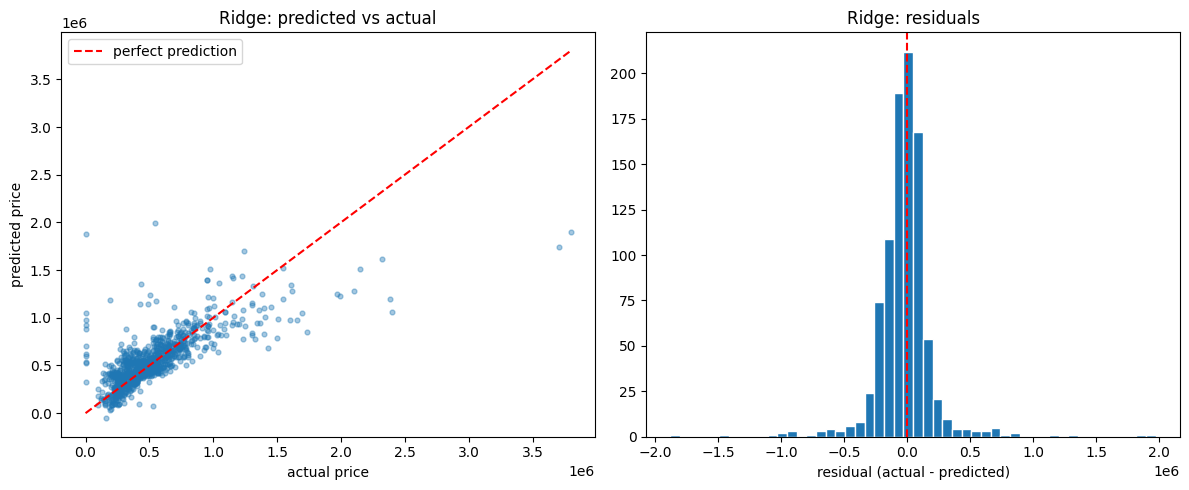

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, ridge_pred, alpha=0.4, s=12)
lims = [0, max(y_test.max(), ridge_pred.max())]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("actual price")
axes[0].set_ylabel("predicted price")
axes[0].set_title("Ridge: predicted vs actual")
axes[0].legend()

residuals = y_test - ridge_pred
axes[1].hist(residuals, bins=50, edgecolor="white")
axes[1].axvline(0, color="r", linestyle="--")
axes[1].set_xlabel("residual (actual - predicted)")
axes[1].set_title("Ridge: residuals")

plt.tight_layout()
plt.show()

## 9. Findings and limits

- The baseline scores R2 = -0.007 on the test split: essentially zero, exactly as expected for a model that always guesses the training average. Linear regression scores 0.567 and Ridge 0.553 (best alpha 10).
- On this data there is no evidence that regularization helps: linear and Ridge are within noise of each other both on the test split and in cross-validation.
- Cross-validation earns its keep. In training-only 5-fold CV, both models swing from about 0.09 to 0.57 R2 depending on the fold (mean about 0.39). A single split can land anywhere in that range, so one split's score says little on its own.
- The most extreme sales dominate the errors. In a fold containing the priciest sale (26.6M for 1,180 sqft, far outside the usual pattern), that one house produced 73% of the fold's squared error, and the three sales above 3M produced 89% of it. That's what a collapsed fold score looks like: a few misses measured in millions.
- The residuals show the same pattern: the biggest misses are the most expensive houses, which the model underprices.

Limits: one metro area over a short period, and plain linear models can't capture interactions (a view may matter more in some cities than others). Tree-based models like random forest or gradient boosting handle that better - they come later in this module.
